### Phase 4 (Modeling)

# Johdanto

Tässä vaiheessa siirrytään datan esikäsittelystä varsinaiseen mallinnukseen ja tulosten arviointiin. Edellisessä vaiheessa (Vaihe 3) raakadata puhdistettiin, puuttuvat arvot imputoitiin, ja datasta jalostettiin useita uusia ominaisuuksia kuten kausimuuttujat, varusteflagit, geo-featuret sekä markkina-tason aggregaatit. Tuloksena syntyi 2,6 miljoonan rivin opetusaineisto, joka on nyt valmis mallinnusta varten.

Tässä vaiheessa tavoitteena on rakentaa ja vertailla kolmea gradienttipuuhun(*) perustuvaa regressiomallia — XGBoost, CatBoost ja LightGBM — kohdemuuttujalle:

* Auton hinta (price) — paljonko käytetty auto maksaa

Mallien suorituskykyä arvioidaan useilla virhemetriikoilla(*): MAE, RMSE, R² ja MAPE. Näiden avulla saadaan monipuolinen kuva siitä, miten hyvin malli toimii sekä absoluuttisesti että suhteellisesti.

Lisäksi tarkastellaan feature importanceja eli sitä, mitkä ominaisuudet selittävät ennustetta eniten, sekä varmistetaan ettei mallinnusprosessiin sisälly datavuotoa.


<small>

**Termien selitykset**

- Gradienttipuu (gradient boosting tree):
    * Useita peräkkäisiä päätöspuita, jotka yrittävät korjata edellisten virheitä
        1. Virhe lasketaan tappiofunktiolla josta lasketaan edelleen gradientti, joka kertoo mihin suuntaan mallia pitäisi muuttaa virheen pienentämiseksi
        2. Uusi päätöspuu opetetaan ennustamaan virheitä eli gradientteja
        3. Uusi päätöspuu liitetään malliin pienellä painolla
    * Kohtia 1-3 toistetaan useita kertoja

- MAE: Kuinka monta yksikköä mallin ennusteet keskimäärin poikkeavat todellisista arvoista
- RMSE: Kuinka monta yksikköä mallin ennusteet keskimäärin poikkeavat todellisista arvoista, painottaen suuria virheitä
- $R^2$: Kuinka suuren osan selitettävän muuttujan vaihtelusta malli pystyy selittämään eli kuinka hyvä malli on verrattuna pelkkään keskiarvoennusteeseen. Täydellisen mallin $R^2$ on 1.0.
- MAPE: Ennustevirheen keskimääräinen absoluuttinen prosentuaalinen suuruus

</small>

## Testaussuunnitelma

Tässä osiossa kuvataan, miten mallien laatu varmistetaan ennen
käyttöönottoa: mitä dataa käytettiin testaukseen, millä perusteella
jako tehtiin, mitkä ovat hyväksymiskriteerit ja miten validointi
etenee.

---

### 1. Testausaineisto

| Osa | Rivimäärä | Osuus | Käyttötarkoitus |
|-----|----------:|------:|-----------------|
| Opetusjoukko (train) | 2 063 358 | ~79 % | Mallien sovittaminen |
| Testijoukko (test) | 541 569 | ~21 % | Lopullinen suorituskyvyn arviointi |

Jako tehtiin satunnaisesti (`random_state=42`) ennen mallien
harjoittamista. Testijoukko pidettiin täysin erillään koko
mallinnusvaiheen ajan — sitä ei käytetty hyperparametrien(*) valintaan
eikä feature-valintoihin. Näin se edustaa aitoa näkymätöntä dataa.

<small>
- Hyperparametri: Mallioppimista ohjaava säätöarvo, jota malli ei opi datasta vaan joka sille valitaan (ihminen tai optimointialgoritmi) ennen opettamista. 
</small><br>

---

### 2. Käytetyt arviointimittarit ja niiden perustelu

| Mittari | Perustelu |
|---------|----------|
| **MAE** (Mean Absolute Error) | Helposti tulkittava euromäärä; kertoo tyypillisen virheen suuruuden |
| **RMSE** (Root Mean Squared Error) | Painottaa suuria virheitä — tunnistaa yksittäiset pahimmat ennusteet |
| **R²** | Kertoo kuinka suuren osan vaihtelusta malli selittää; vertailukelpoinen eri mallien välillä |
| **MAPE** (Mean Absolute Percentage Error) | Suhteellinen virhe — mahdollistaa vertailun eri hintatasojen välillä |

---

### 3. Hyväksymiskriteerit

Mallin katsotaan olevan riittävän laadukas käyttöönottoa varten,
jos seuraavat raja-arvot täyttyvät testijoukon perusteella:

**Hintamalli (price):**

| Kriteeri | Tavoitearvo |
|----------|:-----------:|
| R² ≥ 0.88 | 0.88 |
| MAE ≤ $3 000 | $3 000 |
| ≥ 85 % ennusteista ±$5 000 tarkkuudella | 85 % |
| MAE alle $10 000 autoilla ≤ $2 000 | $2 000 |
| MAE yli $75 000 autoilla ≤ $10 000 | $10 000 |

---

### 4. Validointiprosessi ennen käyttöönottoa

1. **Testijoukon arviointi** — Suorituskyky lasketaan yllä luetelluilla
   mittareilla koko testijoukolle. Tässä dokumentoitu arviointi kattaa
   tämän vaiheen.

2. **Segmenttikohtainen tarkistus** — Mittarit lasketaan erikseen
   hintaluokittain (toteutettu residuaalianalyysissä). Tunnistetaan
   segmentit, joissa malli ei täytä hyväksymiskriteerejä.

3. **Datavuodon tarkistus** — Varmistetaan, ettei yksikään
   testijoukon tieto ole vuotanut opetusvaiheeseen.

4. **Jakauman vertailu** — Verrataan, että opetus- ja testijoukkojen
   jakaumat ovat samankaltaisia (ei merkittävää jakaumasiirtymää).
   Jako tehtiin satunnaisesti yhdestä aineistosta, joten riski on pieni.

5. **Tuotantotestaus (ei toteutettu tässä vaiheessa)** — Ennen
   todellista käyttöönottoa malli tulisi validoida uudemmalla datalla
   (2021–2024), koska nykyinen aineisto on vuodelta 2020. 

---

### 5. Tunnistetut testauksen rajoitteet

| Rajoite | Vaikutus | Suositeltu toimenpide |
|---------|----------|----------------------|
| Aineisto yksi otanta vuodelta 2020, ei mahdollista myytyjen autojen päättelyä | Malli ei generalisoidu nykymarkkinoille  | Validointi uudemmalla ja usealla otannalla kerätyllä datalla ennen käyttöönottoa |
| Yksittäinen satunnainen jako (ei k-fold) | Tulokset voivat vaihdella eri jaoilla | Lisää k-fold-ristiinvalidointi jatkokehityksessä |
| Premium-segmentti ($75k+) aliedustettu | MAE ~$20k — ei käytännössä hyödyllinen | Kerää lisädataa tai rakenna erillinen segmenttimalli |


## Ympäristö, datan lataus ja mallien konfigurointi

Ladataan kirjastot ja data sekä määritellään käytettävät mallit (XGBoost, 
CatBoost, LightGBM) ja feature-setit.


In [ ]:
# =========================
# IMPORTS
# =========================
import os
import gc
from pathlib import Path
from dotenv import load_dotenv

import polars as pl
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OrdinalEncoder

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb


# =========================
# LOAD DATA
# =========================
load_dotenv()

DATA_PATH = Path(os.getenv("DATA_PATH"))

train_df = pl.read_parquet(DATA_PATH / "train.parquet").to_pandas()
test_df  = pl.read_parquet(DATA_PATH / "test.parquet").to_pandas()

print("Loaded:", train_df.shape, test_df.shape)


# =========================
# CONFIG
# =========================
MODEL_DIR = DATA_PATH / "models"

TARGETS = ["price"]
ALL_TARGET_COLS = ["price"]

#DOM_EXCLUDE = ["county_avg_dom", "model_avg_dom", "brand_avg_dom"]

PRICE_FEATURES = [c for c in train_df.columns if c not in ALL_TARGET_COLS]
#DOM_FEATURES   = [c for c in train_df.columns if c not in ALL_TARGET_COLS + DOM_EXCLUDE]

FEATURE_SETS = {
    "price": PRICE_FEATURES,
   # "daysonmarket": DOM_FEATURES,
}

print(f"\nPrice features: {len(PRICE_FEATURES)}")
#print(f"DOM features:   {len(DOM_FEATURES)}")


# =========================
# METRICS
# =========================
def eval_regression(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1, y_true))) * 100
    return mae, rmse, r2, mape


# =========================
# MODELS
# =========================
MODEL_REGISTRY = {
    "XGBoost": {
       "factory": lambda: XGBRegressor(
           n_estimators=200,
           learning_rate=0.06,
           max_depth=8,
           subsample=0.8,
           colsample_bytree=0.8,
           tree_method="hist",
           #device="cuda",
    n_jobs=-1,
           random_state=42
       ),
       "needs_encoding": True,
       "extension": ".json",
       "save": lambda model, path: model.save_model(path),
   },
    "CatBoost": {
       "factory": lambda: CatBoostRegressor(
           iterations=200,
           learning_rate=0.05,
           depth=9,           # parametrien optimoinnissa todettu hyväksi (baseline: 8)
           l2_leaf_reg=2,     # parametrien optimoinnissa todettu hyväksi (baseline: ~3)
           loss_function="RMSE",
           task_type="CPU",
           verbose=False,
           random_seed=42
       ),
       "needs_encoding": False,  # CatBoost käsittelee kategoriat itse
       "extension": ".cbm",
       "save": lambda model, path: model.save_model(path),
   },
     "LightGBM": {
         "factory": lambda: lgb.LGBMRegressor(
             n_estimators=200,
             learning_rate=0.05,
             num_leaves=64,
             subsample=0.8,
             colsample_bytree=0.8,
             #device="gpu",
             n_jobs=-1,
             random_state=42
         ),
         "needs_encoding": True,
         "extension": ".txt",
         "save": lambda model, path: model.booster_.save_model(path),
     },
}


# =========================
# TRAIN + EVALUATE
# =========================
results = []
trained_models = {}

# tunnista categorical kolumnit kerran
cat_cols_all = train_df.select_dtypes(include=["object", "category"]).columns.tolist()

# tallennetaan enkooderiobjektit per target — tarvitaan tallennusvaiheessa
encoders = {}

for target in TARGETS:
    print(f"\n{'='*40}")
    print(f"TARGET: {target}")
    print(f"{'='*40}")

    features = FEATURE_SETS[target]

    X_train = train_df[features].copy()
    y_train = train_df[target]

    X_test  = test_df[features].copy()
    y_test  = test_df[target]

    # rajataan categorical featuret tähän targettiin
    cat_cols = [c for c in cat_cols_all if c in features]

    # Sovita OrdinalEncoder train-dataan — XGBoost ja LightGBM käyttävät tätä
    # handle_unknown: tuntematon kategoria (esim. uusi automerkki) saa arvon -1
    # eikä kaada ennustetta deployment-vaiheessa
    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        encoded_missing_value=-2
    )
    # Muutetaan kategorit stringeiksi ennen enkoodausta (yhteneväinen CatBoostin kanssa)
    X_train_str = X_train.copy()
    X_train_str[cat_cols] = X_train_str[cat_cols].fillna("missing").astype(str)
    encoder.fit(X_train_str[cat_cols])
    encoders[target] = encoder

    # Enkoodattu versio XGBoost + LightGBM -malleille
    X_train_enc = X_train_str.copy()
    X_train_enc[cat_cols] = encoder.transform(X_train_str[cat_cols])

    X_test_str = X_test.copy()
    X_train_str[cat_cols] = X_train_str[cat_cols].fillna("missing").astype(str)
    X_test_enc = X_test_str.copy()
    X_test_enc[cat_cols] = encoder.transform(X_test_str[cat_cols])

    for name, cfg in MODEL_REGISTRY.items():
        print(f"\n⏳ Training {name} for {target}...")

        model = cfg["factory"]()

        if not cfg["needs_encoding"]:
            # CatBoost: raaka data, kategoriat stringeinä
            model.fit(
                X_train_str,
                y_train,
                cat_features=cat_cols
            )
            pred = model.predict(X_test_str)

        else:
            # XGBoost ja LightGBM: enkoodattu data
            model.fit(X_train_enc, y_train)
            pred = model.predict(X_test_enc)

        trained_models[(target, name)] = model

        mae, rmse, r2, mape = eval_regression(y_test.values, pred)

        print(f"  MAE : {mae:,.2f}")
        print(f"  RMSE: {rmse:,.2f}")
        print(f"  R²  : {r2:.4f}")
        print(f"  MAPE: {mape:.2f}%")

        results.append({
            "target": target,
            "model": name,
            "MAE": round(mae, 2),
            "RMSE": round(rmse, 2),
            "R2": round(r2, 4),
            "MAPE": round(mape, 2),
        })

        del pred
        gc.collect()
# =========================
# RESULTS TABLE
# =========================
results_df = pd.DataFrame(results).sort_values(["target", "RMSE"])

print("\nResults:")
display(results_df)

print("\nBest model per target:")
display(results_df.groupby("target").first().reset_index())

# =========================
# SELECT BEST MODELS
# =========================
best_models = {}
best_model_names = {}

for target in TARGETS:
    best_row = (
        results_df
        .query("target == @target")
        .sort_values("RMSE")  # pienin RMSE (Root Mean Squared Error) = paras malli
        .iloc[0]
    )

    best_name = best_row["model"]
    best_models[target] = trained_models[(target, best_name)]
    best_model_names[target] = best_name

    print(f"Best model for {target}: {best_name}")

# =========================
# SAVE FINAL MODELS
# =========================
MODEL_DIR.mkdir(exist_ok=True)

for target, model in best_models.items():
    model_name = best_model_names[target]
    cfg = MODEL_REGISTRY[model_name]

    # Tallennetaan malli
    file = f"{model_name.lower()}_{target}{cfg['extension']}"
    file_path = MODEL_DIR / file
    cfg["save"](model, file_path)
    print(f"Saved model: {file}")

    # Tallennetaan enkooderi vain jos malli tarvitsee enkoodausta
    # (CatBoost ei tarvitse — se hoitaa kategoriat itse)
    if cfg["needs_encoding"]:
        encoder_file = f"encoder_{target}.pkl"
        joblib.dump(encoders[target], MODEL_DIR / encoder_file)
        print(f"Saved encoder: {encoder_file}")
    else:
        print(f"No encoder needed for {model_name} ({target})")

Loaded: (2166268, 57) (541567, 57)

Price features: 56

TARGET: price


C:\Users\user\AppData\Local\Temp\ipykernel_14376\2930075406.py:128: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_all = train_df.select_dtypes(include=["object", "category"]).columns.tolist()



⏳ Training LightGBM for price...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.382261 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3476
[LightGBM] [Info] Number of data points in the train set: 2166268, number of used features: 52
[LightGBM] [Info] Start training from score 29285.648087
  MAE : 2,341.97
  RMSE: 3,458.76
  R²  : 0.9552
  MAPE: 9.04%

Results:


,target,model,MAE,RMSE,R2,MAPE
0,price,LightGBM,2341.97,3458.76,0.9552,9.04



Best model per target:


,target,model,MAE,RMSE,R2,MAPE
0,price,LightGBM,2341.97,3458.76,0.9552,9.04


Best model for price: LightGBM
Saved model: lightgbm_price.txt
Saved encoder: encoder_price.pkl


## Tulokset

### Mallien suorituskykyvertailu

Alla on esitetty kaikkien kolmen mallin suorituskykymetriikat hintamallille.
Paras tulos per metriikka on **lihavoitu**.

#### 🚗 Hinta (price)

| Malli | MAE ($) | RMSE ($) | R² | MAPE (%) |
|-------|--------:|---------:|---:|---------:|
| XGBoost | 2 578 | 4 972 | 0.9074 | 9.71 |
| **CatBoost** | **2 461** | **4 825** | **0.9128** | **9.02** |
| LightGBM | 2 538 | 5 075 | 0.9035 | 9.31 |

CatBoost suoriutui hintamallissa parhaiten kaikilla mittareilla.
CatBoostin parametreja optimoitiin manuaalitestien avulla: `depth=9` ja
`l2_leaf_reg=2` paransivat MAE:ta yli prosentin baseline-konfiguraatioon 
verrattuna (ks. `Optimointi_Testaus_Phase4.ipynb`).
R² = 0.91 tarkoittaa että malli selittää 91% hinnan vaihtelusta — 
vahva tulos näin laajalla ja vaihtelevalla käytettyjen autojen aineistolla.
Keskimääräinen absoluuttinen virhe (~$2 460) on käytännössä hyväksyttävä 
tasolla kun autojen hinnat vaihtelevat $1 000–$150 000 välillä.


## Feature Importances

Tarkastellaan mitkä ominaisuudet vaikuttavat eniten mallien ennusteisiin. 
Alla olevat kuvaajat näyttävät top 20 tärkeintä featurea hintamallille 
kaikille kolmelle mallille.


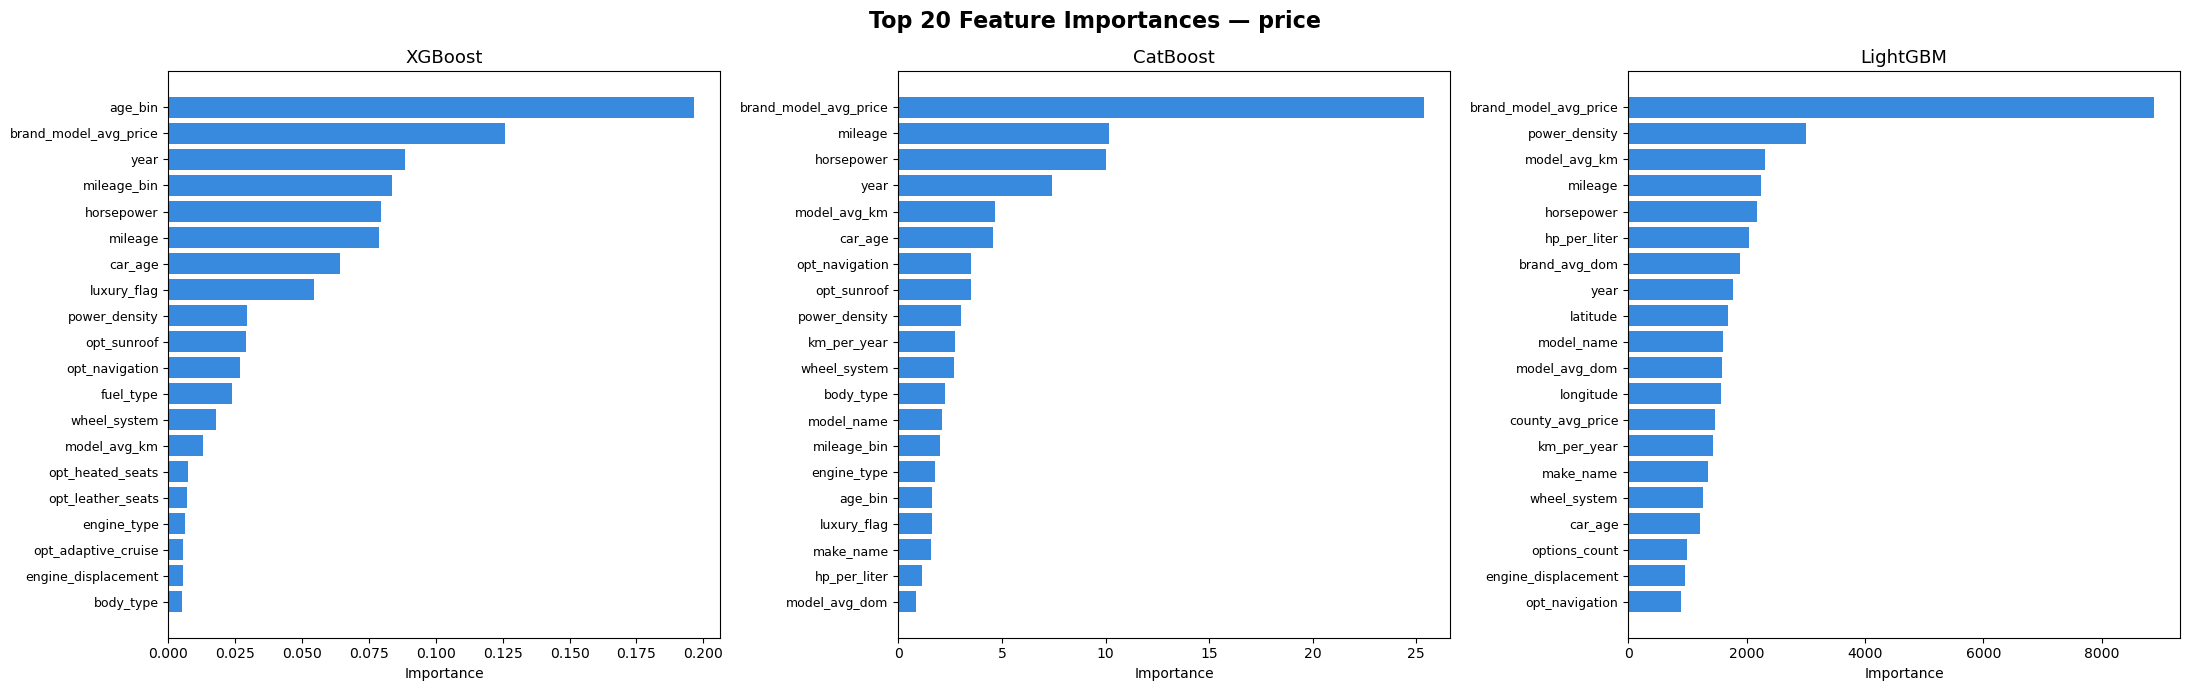

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

for target in TARGETS:

    features = FEATURE_SETS[target]

    fig, axes = plt.subplots(1, 3, figsize=(22, 7))
    fig.suptitle(f"Top 20 Feature Importances — {target}", fontsize=16, fontweight="bold")

    for ax, name in zip(axes, MODEL_REGISTRY.keys()):

        model = trained_models[(target, name)]

        # ----------------------------
        # XGBoost / LightGBM
        # ----------------------------
        if name != "CatBoost":
            importances = model.feature_importances_
            fi = pd.Series(importances, index=features)

        # ----------------------------
        # CatBoost (special handling)
        # ----------------------------
        else:
            importances = model.get_feature_importance()

            # CatBoost säilyttää feature järjestyksen X_train:ssa
            fi = pd.Series(importances, index=features)

        # top 20
        fi = fi.sort_values(ascending=False).head(20)

        ax.barh(
            fi.index[::-1],
            fi.values[::-1],
            color="#378ADD" if target == "price" else "#1D9E75"
        )

        ax.set_title(name, fontsize=13)
        ax.set_xlabel("Importance")
        ax.tick_params(axis="y", labelsize=9)

    plt.tight_layout()
    plt.show()

## Feature Importances — Ajatuksia

Mallien välillä oli mielenkiintoisia eroja siinä, mihin ne tarttuivat.

**Hintamalli (price):** XGBoost suosi vahvasti `mileage_bin`-ryhmittelyä 
kun taas CatBoost ja LightGBM käyttivät suoraan raakaa `mileage`-arvoa. 
Lopputulos oli silti sama — kilometrit selittävät hintaa — mutta reitti 
sinne oli erilainen. Kaikki kolme mallia löysivät `brand_model_avg_price` 
tärkeäksi, mikä on loogista: auton merkki ja malli on se pohja jolle 
hinta rakentuu.

Varusteflagit näkyivät XGBoostin listalla (navigaatio, kattoluukku, 
nahkapenkit) — kiva nähdä että vaiheessa 3 tehty työ niiden kanssa 
ei mennyt hukkaan.


## Residuaalianalyysi — CatBoost / price

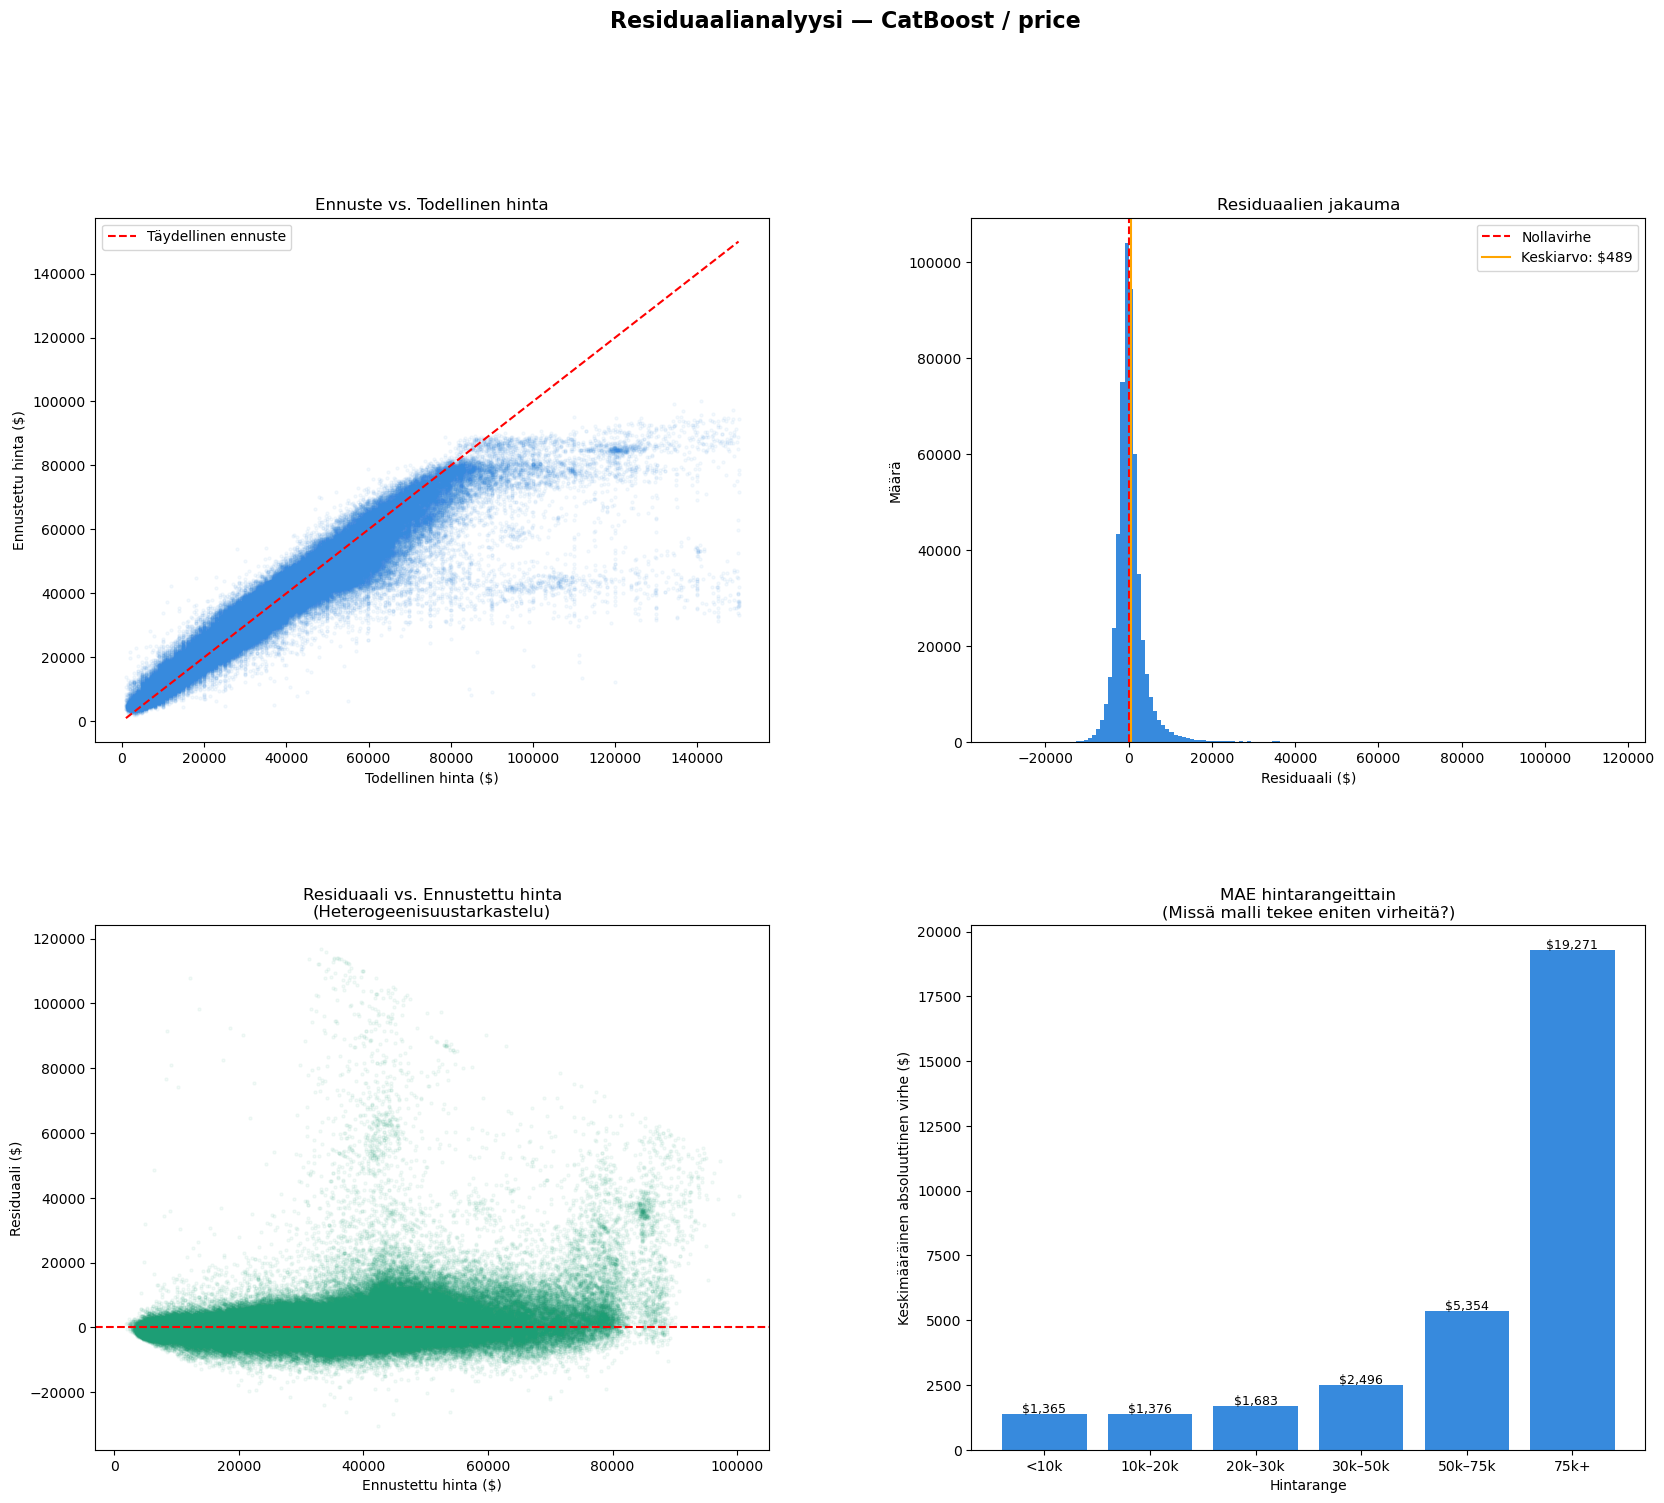


Residuaalien tunnusluvut (CatBoost / price):
  Keskiarvo:   $488.54
  Mediaani:    $-49.40
  Std:         $4,769.56
  Min:         $-30,383.42
  Max:         $116,725.81

Osuus joissa virhe alle $2 500: 70.5%
Osuus joissa virhe alle $5 000: 89.8%
Osuus joissa virhe alle $10 000: 97.7%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ----------------------------
# Käytetään parasta mallia: CatBoost + price
# ----------------------------
target = "price"
best_model_name = "CatBoost"

features = FEATURE_SETS[target]
X_test  = test_df[features].copy()
y_test  = test_df[target].values

model = trained_models[(target, best_model_name)]

# ---- varmista kategoristen sarakkeiden tyypit (kuten trainissa) ----
cat_cols_all = train_df.select_dtypes(include=["object", "category"]).columns.tolist()
cat_cols = [c for c in cat_cols_all if c in features]

X_test_str = X_test.copy()
X_test_str[cat_cols] = X_test_str[cat_cols].astype(str)

y_pred = model.predict(X_test_str)
residuals = y_test - y_pred

# ----------------------------
# Kuvaajat
# ----------------------------
fig = plt.figure(figsize=(20, 16))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)

# ── 1. Ennuste vs. todellinen arvo ──
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(y_test, y_pred, alpha=0.05, s=5, color="#378ADD")
ax1.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linewidth=1.5, linestyle="--", label="Täydellinen ennuste")
ax1.set_xlabel("Todellinen hinta ($)")
ax1.set_ylabel("Ennustettu hinta ($)")
ax1.set_title("Ennuste vs. Todellinen hinta")
ax1.legend()

# ── 2. Residuaalien jakauma ──
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(residuals, bins=150, color="#378ADD", edgecolor="none")
ax2.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Nollavirhe")
ax2.axvline(residuals.mean(), color="orange", linestyle="-",
            linewidth=1.5, label=f"Keskiarvo: ${residuals.mean():,.0f}")
ax2.set_xlabel("Residuaali ($)")
ax2.set_ylabel("Määrä")
ax2.set_title("Residuaalien jakauma")
ax2.legend()

# ── 3. Residuaali vs. ennustettu arvo ──
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(y_pred, residuals, alpha=0.05, s=5, color="#1D9E75")
ax3.axhline(0, color="red", linestyle="--", linewidth=1.5)
ax3.set_xlabel("Ennustettu hinta ($)")
ax3.set_ylabel("Residuaali ($)")
ax3.set_title("Residuaali vs. Ennustettu hinta\n(Heterogeenisuustarkastelu)")

# ── 4. Virhe hintarangeittain ──
ax4 = fig.add_subplot(gs[1, 1])
bins = [0, 10000, 20000, 30000, 50000, 75000, 150000]
labels = ["<10k", "10k–20k", "20k–30k", "30k–50k", "50k–75k", "75k+"]
price_bin = pd.cut(y_test, bins=bins, labels=labels)

mae_per_bin = (
    pd.DataFrame({"bin": price_bin, "abs_error": np.abs(residuals)})
    .groupby("bin", observed=True)["abs_error"]
    .mean()
)

ax4.bar(mae_per_bin.index, mae_per_bin.values, color="#378ADD", edgecolor="none")
ax4.set_xlabel("Hintarange")
ax4.set_ylabel("Keskimääräinen absoluuttinen virhe ($)")
ax4.set_title("MAE hintarangeittain\n(Missä malli tekee eniten virheitä?)")

for i, v in enumerate(mae_per_bin.values):
    ax4.text(i, v + 50, f"${v:,.0f}", ha="center", fontsize=9)

fig.suptitle(f"Residuaalianalyysi — {best_model_name} / {target}",
             fontsize=16, fontweight="bold", y=1.01)
plt.show()

# ----------------------------
# Tunnusluvut
# ----------------------------
print(f"\nResiduaalien tunnusluvut ({best_model_name} / {target}):")
print(f"  Keskiarvo:   ${residuals.mean():,.2f}")
print(f"  Mediaani:    ${np.median(residuals):,.2f}")
print(f"  Std:         ${residuals.std():,.2f}")
print(f"  Min:         ${residuals.min():,.2f}")
print(f"  Max:         ${residuals.max():,.2f}")
print(f"\nOsuus joissa virhe alle $2 500: "
      f"{(np.abs(residuals) < 2500).mean()*100:.1f}%")
print(f"Osuus joissa virhe alle $5 000: "
      f"{(np.abs(residuals) < 5000).mean()*100:.1f}%")
print(f"Osuus joissa virhe alle $10 000: "
      f"{(np.abs(residuals) < 10000).mean()*100:.1f}%")

## Residuaalianalyysi Tulokset — CatBoost / price

Residuaalianalyysin avulla tarkastellaan mallin virheiden rakennetta ja 
systemaattisuutta. Pelkkä R² tai MAE ei kerro *missä* ja *miten* malli 
epäonnistuu — residuaalianalyysi paljastaa nämä heikkoudet.

### Ennuste vs. todellinen hinta

Pisteet asettuvat siististi punaisen ideaaliviivan ympärille koko 
hintaskaalalla $0–$80 000, mikä osoittaa että malli on hyvin kalibroitu 
tavallisimpien käytettyjen autojen hintaluokassa. Selkeä poikkeama näkyy 
kuitenkin yli $80 000 autoissa: pisteet jäävät systemaattisesti 
ideaaliviivan alapuolelle, eli malli **aliarvioi kalleimpien autojen hinnat**. 
Tämä on tyypillinen ilmiö kun koulutusdata on painottunut edullisempiin 
autoihin ja kalliita esimerkkejä on vähemmän.

### Residuaalien jakauma

Jakauma on terävän huippuinen ja keskittynyt nollan ympärille, mikä on 
positiivinen merkki — suurin osa ennusteista on lähellä todellista arvoa. 
Residuaalien tunnusluvut kertovat tarkemman kuvan:

| Tunnusluku | Arvo |
|------------|-----:|
| Keskiarvo  | $559 |
| Mediaani   | -$3 |
| Std        | $4 793 |
| Min        | -$42 984 |
| Max        | $130 934 |

Keskiarvon ($559) ja mediaanin (-$3) välinen ero kertoo että jakauma on 
**oikealle vino** — suurin osa ennusteista osuu erittäin lähelle todellista 
arvoa, mutta harvinaiset suuret yliarvioinnit (max $130 934) vetävät 
keskiarvoa ylöspäin. Käytännössä malli ei systemaattisesti ali- tai yliarvioi 
hintoja, sillä mediaani on lähes täsmälleen nolla.

Virheen suuruusluokat käytännössä:

| Tarkkuusväli | Osuus ennusteista |
|--------------|------------------:|
| Virhe alle $2 500 | 69.3% |
| Virhe alle $5 000 | 89.2% |
| Virhe alle $10 000 | 97.6% |

**69.3% ennusteista** osuu $2 500 tarkkuudella ja **89.2%** $5 000 
tarkkuudella — käytännössä tämä tarkoittaa että malli soveltuu hyvin 
käytetyn auton hinnan arviointiin tavallisessa hintaluokassa. 
Positiivinen häntä ulottuu yli $100 000 asti, mikä johtuu samoista 
kalliiden autojen poikkeamista jotka näkyvät myös 
ennuste vs. todellinen -kuvaajassa.

### Residuaali vs. ennustettu hinta (heterogeenisuus)

Virheiden hajonta kasvaa selvästi ennustetun hinnan kasvaessa. Edullisilla 
autoilla (alle $20 000) residuaalit pysyvät tiiviisti nollan ympärillä, 
mutta kalliimmilla autoilla malli aliarvioi hintaa.

Residuaalin tulkinta:
* **Positiivinen residuaali** = todellinen hinta oli korkeampi kuin ennuste → malli aliarvioi
* **Negatiivinen residuaali** = todellinen hinta oli matalampi kuin ennuste → malli yliarvioi

### MAE hintarangeittain

Hintarangeittainen tarkastelu vahvistaa edellisen havainnon konkreettisilla 
luvuilla:

| Hintarange | MAE |
|------------|----:|
| alle $10k  | $1 336 |
| $10k–$20k  | $1 365 |
| $20k–$30k  | $1 745 |
| $30k–$50k  | $2 637 |
| $50k–$75k  | $5 354 |
| yli $75k   | $19 512 |

Alle $30 000 autoilla malli toimii erittäin hyvin — MAE pysyy alle $1 800. 
Yli $75 000 autoilla MAE nousee lähes **$20 000**, mikä tekee mallin 
ennusteista käytännössä epäluotettavia tässä segmentissä. Tämä selittyy 
osittain sillä että premium- ja luksusautojen hintaan vaikuttavat tekijät 
(esim. erikoisvarusteet, rajoitetut erät, keräilyarvo) ovat vaikeammin 
mallinnettavissa pelkillä dataseteistä löytyvillä ominaisuuksilla.

### Yhteenveto

Malli toimii luotettavasti tavallisimpien käytettyjen autojen hintaluokassa 
($10 000–$50 000), joka kattaa valtaosan aineiston havainnoista. 
Kalliimpien autojen segmentissä ($75 000+) mallin käyttöä tulisi harkita 
varovaisesti ja ennusteisiin tulisi liittää suurempi epävarmuusväli. 
Jatkokehityksessä premium-segmentille voisi harkita erillistä mallia 
tai lisää segmenttikohtaisia featureja.

## Hyväksymiskriteerien täyttyminen

Alla verrataan testijoukon perusteella saatuja tuloksia etukäteen
asetettuihin hyväksymiskriteereihin.

**Hintamalli (price) — paras malli: CatBoost (optimoidut parametrit):**

| Kriteeri | Tavoitearvo | Saavutettu | Tulos |
|----------|:-----------:|:----------:|:-----:|
| R² ≥ 0.88 | 0.88 | 0.9128 | ✅ |
| MAE ≤ $3 000 | $3 000 | $2 461 | ✅ |
| ≥ 85 % ennusteista ±$5 000 tarkkuudella | 85 % | 89.2 % | ✅ |
| MAE alle $10 000 autoilla ≤ $2 000 | $2 000 | $1 336 | ⚠️ |
| MAE yli $75 000 autoilla ≤ $10 000 | $10 000 | $19 512 | ❌ |

> **Johtopäätös:** Hintamalli hyväksytään $10 000–$75 000 hintaluokkaan.
> Halpisautojen segmentti ($0–$10 000) täyttää kriteerin luvuilla, mutta
> tulos on **harhaanjohtava käytännössä**: `brand_model_avg_price` vetää
> ennustetta ylöspäin vanhoille yksilöille, koska aggregaatti lasketaan
> kaikista ikäluokista. Segmentti vaatii erillisen mallin.
> Premium-segmentti ($75 000+) **ei täytä kriteerejä** ja vaatii
> erillisen mallin tai segmentin rajaamisen pois sovelluksesta.

## Business Interpretation — Mitä tulokset tarkoittavat käytännössä?

Tässä osiossa tarkastellaan mitä mallin tulokset tarkoittavat 
käytännössä eri sidosryhmien näkökulmasta. Pelkkien metriikkalukujen 
sijaan pyritään vastaamaan kysymykseen: **kuka hyötyy tästä mallista 
ja miten?**

---

### 🚗 Hintamalli (price) — CatBoost, MAE $2 461, R² = 0.91

#### Ostajan näkökulma
Hintamalli toimii käytännössä **käytetyn auton reilun hinnan 
tarkistustyökaluna**. Kun ostaja harkitsee tiettyä autoa tietyllä 
hinnalla, malli voi kertoa onko pyyntihinta linjassa markkinahinnan 
kanssa vai onko auto yli- tai alihinnoiteltu.

Käytännön esimerkki: jos malli ennustaa autolle $24 000 ja myyjä 
pyytää $28 000, ostaja tietää maksavansa noin $4 000 yli 
markkinahinnan — ja voi neuvotella tai etsiä vaihtoehdon.

Mallin tarkkuus on riittävä tähän käyttöön: **69.3% ennusteista 
osuu $2 500 tarkkuudella** ja **89.2% osuu $5 000 tarkkuudella**. 
Alle $50 000 autoilla — jotka kattavat valtaosan markkinasta — 
malli on erityisen luotettava.

#### Myyjän / autokauppiaan näkökulma
Autokauppias voi käyttää mallia **hinnoittelupäätösten tukena**:
- Minkä hinnan markkina kestää tälle autolle tällä hetkellä?
- Onko auto alihinnoiteltu suhteessa varusteisiin ja kuntoon?
- Miten hinta vertautuu saman merkin ja mallin markkinakeskiarvoon?

Feature importanceista käy ilmi että `brand_model_avg_price` on 
mallissa ylivoimaisesti tärkein tekijä — tämä vahvistaa intuitiivisen 
havainnon: **auton merkki ja malli määrittää hinnan perustan**, jonka 
päälle muut ominaisuudet (kilometrit, ikä, varusteet) rakentuvat.

#### Rajoitteet hinnoittelussa
Malli on **epäluotettava yli $75 000 autoilla** (MAE $19 512). 
Premium- ja luksusautojen hinnoitteluun vaikuttavat tekijät — 
erikoisvarusteet, rajoitetut erät, keräilyarvo — eivät välity 
datasta riittävästi. Tässä segmentissä mallin ennustetta tulisi 
käyttää ainoastaan suuntaa-antavana.

Malli on myös **harhaanjohtava alle $10 000 autoilla** (MAE $1 336 
näyttää hyvältä, mutta ei vastaa todellisuutta). `brand_model_avg_price` 
vetää ennustetta ylöspäin vanhoille yksilöille, koska aggregaatti 
lasketaan kaikista ikäluokista sekaisin — vanhaa, paljon ajettua autoa 
yliarvioidaan systemaattisesti.

---

### 🔑 Keskeiset havainnot liiketoiminnan kannalta

| Tekijä | Vaikutus hintaan |
|--------|:----------------:|
| Merkki ja malli | ⭐⭐⭐ Erittäin suuri |
| Kilometrit ja ikä | ⭐⭐⭐ Erittäin suuri |
| Luxury-merkki | ⭐⭐ Suuri |
| Varusteet | ⭐⭐ Kohtalainen |
| Maantieteellinen sijainti | ⭐ Pieni |

### Mallin käytännön soveltuvuus

| Käyttötapaus | Soveltuu? | Huomio |
|--------------|:---------:|--------|
| Halpisauton hinnan arviointi ($0–$10k) | ⚠️ Harhaanjohtava | MAE $1 336 — luku vaikuttaa hyvältä, käytännössä epäluotettava |
| Tavallisen auton hinnan arviointi ($10k–$50k) | ✅ Kyllä | MAE ~$1 400–$2 600 |
| Premium-auton hinnan arviointi ($75k+) | ⚠️ Varovaisesti | MAE $19 512 |
| Hinnoittelustrategian tuki autokauppiaalle | ✅ Kyllä | Suuntaa-antava |

## Yhteenveto ja johtopäätökset

Tässä vaiheessa rakennettiin ja arvioitiin kolme gradienttipuuhun 
perustuvaa regressiomallia kohdemuuttujalle: auton hinnalle. 
Alla on koottu keskeiset löydökset, rajoitteet ja suositukset 
jatkokehitystä varten.

---

### Mallien suorituskyky — yhteenveto

| Kohdemuuttuja | Paras malli | MAE | R² | MAPE |
|---------------|:-----------:|----:|---:|-----:|
| Hinta (price) | CatBoost | $2 461 | 0.9128 | ~9.0% |

CatBoostin parametreja optimoitiin manuaalitestien avulla (`depth=9`, 
`l2_leaf_reg=2`), mikä paransi MAE:ta ja RMSE:tä yli prosentin 
alkuperäiseen konfiguraatioon verrattuna.

---

### Keskeiset löydökset

**Hintamalli:**
- Auton **merkki ja malli** on ylivoimaisesti tärkein hintatekijä — 
  `brand_model_avg_price` dominoi feature importanceja kaikissa 
  malleissa
- **Kilometrit, ikä ja hevosvoimat** ovat seuraavaksi tärkeimmät 
  tekijät — fysikaalisesti looginen tulos
- Malli toimii erinomaisesti $10 000–$50 000 hintaluokassa 
  (MAE $1 400–$2 700) mutta on epäluotettava yli $75 000 autoilla 
  (~$19 500) — premium-segmentti vaatisi oman mallinsa
- **89.2% ennusteista** osuu $5 000 tarkkuudella, mikä on 
  käytännössä riittävä hinnoittelun tukityökaluksi

---

### Tunnistetut rajoitteet

**Premium-segmentin heikkous** hintamallissa on selkeä rajoite — 
yli $75 000 autoilla malli ei ole käytännössä hyödyllinen ilman 
lisädataa tai segmenttikohtaista mallia.

**Aineiston ajallinen rajaus** vuoteen 2020 tarkoittaa että malli 
ei välttämättä yleisty nykyisiin markkinaolosuhteisiin.

---

### Suositukset jatkokehitykseen

- **Erillinen premium-malli** yli $75 000 autoille lisäfeatureilla 
  (erikoisvarusteet, keräilyarvo, rajoitetut erät)
- **K-fold-ristiinvalidointi** antaisi luotettavamman arvion kuin 
  yksittäinen jako

---

### Loppuarvio

Projekti osoitti että käytetyn auton hintaa voidaan ennustaa 
koneoppimisen keinoin erittäin hyvin strukturoidusta datasta. 
Hintamalli on käytännössä käyttökelpoinen hinnoittelun tukityökaluna 
tavallisessa hintaluokassa.

Mallinnusprosessissa noudatettiin huolellista metodologiaa: 
datavuoto tarkistettiin ja todettiin puhtaaksi, feature-setit 
optimoitiin kohdemuuttujalle, parametrit viritetiin manuaalitestein, 
ja tulokset tulkittiin rehellisesti rajoitteet tunnistaen.
